Loading data from: c:\Users\6cc\Desktop\ama2233-hk-summer-weather-main\ama2233-hk-summer-weather-main\data\metrics\annual_summer_metrics.csv
Figures successfully generated and saved to:
- c:\Users\6cc\Desktop\ama2233-hk-summer-weather-main\ama2233-hk-summer-weather-main\figures\02_summer_rainfall_trend.png
- c:\Users\6cc\Desktop\ama2233-hk-summer-weather-main\ama2233-hk-summer-weather-main\figures\02_summer_rainfall_trend.svg


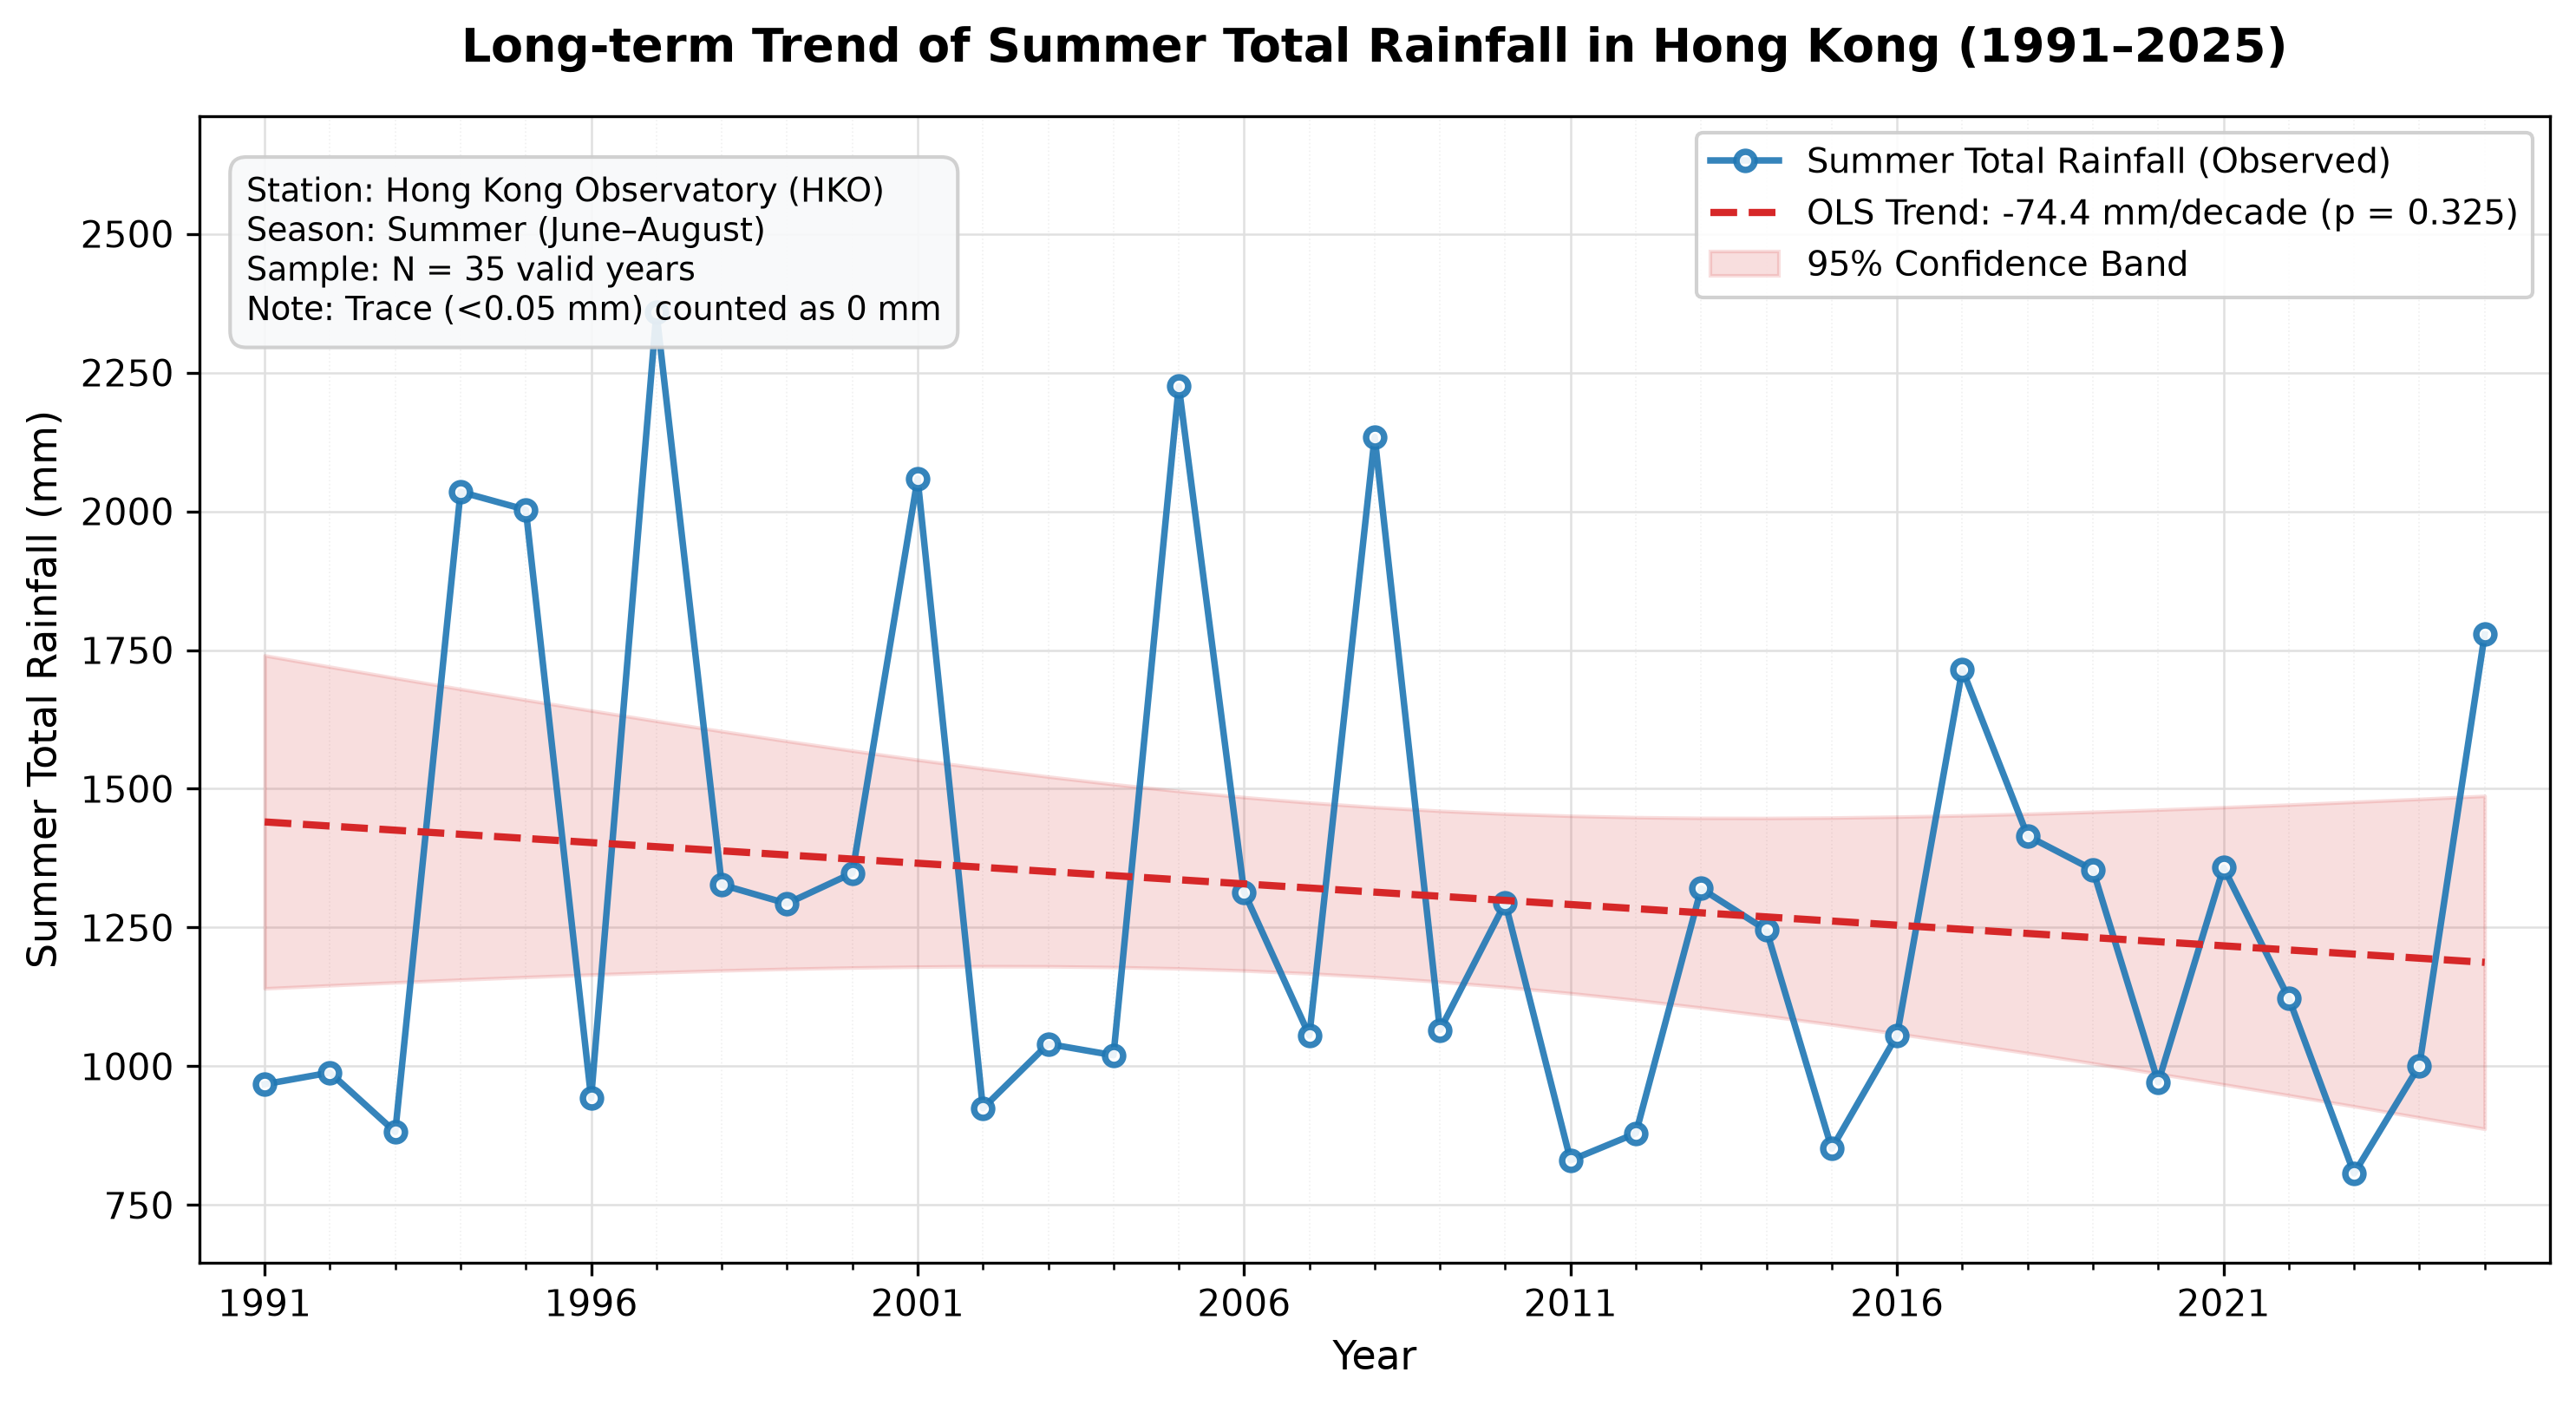

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


current_directory = Path.cwd()
project_root = (
    current_directory
    if (current_directory / "pyproject.toml").exists()
    else current_directory.parent
)

data_path = project_root / "data" / "metrics" / "annual_summer_metrics.csv"
figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

print(f"Loading data from: {data_path}")
df_annual = pd.read_csv(data_path)


year_col = [c for c in df_annual.columns if "year" in c.lower()][0]
rainfall_col = [
    c
    for c in df_annual.columns
    if any(k in c.lower() for k in ["rain", "rf", "precip"])
    and "day" not in c.lower()
][0]


df_plot = (
    df_annual[(df_annual[year_col] >= 1991) & (df_annual[year_col] <= 2025)]
    .dropna(subset=[year_col, rainfall_col])
    .sort_values(by=year_col)
    .copy()
)

years = df_plot[year_col].values
rainfall = df_plot[rainfall_col].values
n_years = len(years)


slope, intercept, r_value, p_value, std_err = stats.linregress(years, rainfall)
trend_line = slope * years + intercept
decadal_change = slope * 10
t_val = stats.t.ppf(0.975, df=n_years - 2)
x_mean = np.mean(years)
s_err = np.sqrt(np.sum((rainfall - trend_line) ** 2) / (n_years - 2))
ci = (
    t_val
    * s_err
    * np.sqrt(1 / n_years + (years - x_mean) ** 2 / np.sum((years - x_mean) ** 2))
)

p_display = (
    f"p = {p_value:.3f}" if p_value >= 0.001 else "p < 0.001 (Significant)"
)
trend_sign = "+" if decadal_change >= 0 else ""
trend_label = (
    f"OLS Trend: {trend_sign}{decadal_change:.1f} mm/decade ({p_display})"
)


plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)
COLOR_MAIN = "#1f77b4"
COLOR_TREND = "#d62728"
COLOR_GRID = "#e0e0e0"


ax.plot(
    years,
    rainfall,
    color=COLOR_MAIN,
    linewidth=1.8,
    marker="o",
    markersize=5,
    markerfacecolor="#ffffff",
    markeredgewidth=1.8,
    markeredgecolor=COLOR_MAIN,
    alpha=0.9,
    label="Summer Total Rainfall (Observed)",
    zorder=3,
)


ax.plot(
    years,
    trend_line,
    color=COLOR_TREND,
    linestyle="--",
    linewidth=2.0,
    label=trend_label,
    zorder=4,
)
ax.fill_between(
    years,
    trend_line - ci,
    trend_line + ci,
    color=COLOR_TREND,
    alpha=0.15,
    label="95% Confidence Band",
    zorder=2,
)


ax.set_xlim(1990, 2026)
ax.set_xticks(range(1991, 2026, 5))
ax.set_xticks(range(1991, 2026, 1), minor=True)
ax.set_ylim(max(0, rainfall.min() * 0.8), rainfall.max() * 1.15)

ax.set_title(
    "Long-term Trend of Summer Total Rainfall in Hong Kong (1991–2025)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Year", fontsize=11, fontweight="medium")
ax.set_ylabel("Summer Total Rainfall (mm)", fontsize=11, fontweight="medium")


meta_text = (
    "Station: Hong Kong Observatory (HKO)\n"
    "Season: Summer (June–August)\n"
    f"Sample: N = {n_years} valid years\n"
    "Note: Trace (<0.05 mm) counted as 0 mm"
)
ax.text(
    0.02,
    0.95,
    meta_text,
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#f8f9fa",
        edgecolor="#cccccc",
        alpha=0.9,
    ),
    zorder=5,
)

ax.grid(True, which="major", linestyle="-", linewidth=0.6, color=COLOR_GRID)
ax.grid(True, which="minor", linestyle=":", linewidth=0.4, color="#f0f0f0")
ax.set_axisbelow(True)
ax.legend(loc="upper right", frameon=True, framealpha=0.9, fontsize=9.5)

plt.tight_layout()


output_png = figures_dir / "02_summer_rainfall_trend.png"
output_svg = figures_dir / "02_summer_rainfall_trend.svg"
fig.savefig(output_png, dpi=300, bbox_inches="tight")
fig.savefig(output_svg, format="svg", bbox_inches="tight")

print(f"Figures successfully generated and saved to:\n- {output_png}\n- {output_svg}")
plt.show()
